<a href="https://colab.research.google.com/github/vanesamrd/ML_ganjil/blob/main/Vanesa_JS6_T01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Memuat dataset
# Pastikan file insurance.csv berada di direktori aktif Anda
try:
    df = pd.read_csv('insurance.csv')
    print("Dataset berhasil dimuat!")
    display(df.head())
except FileNotFoundError:
    print("File insurance.csv tidak ditemukan. Harap unggah file tersebut terlebih dahulu.")

Dataset berhasil dimuat!


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None


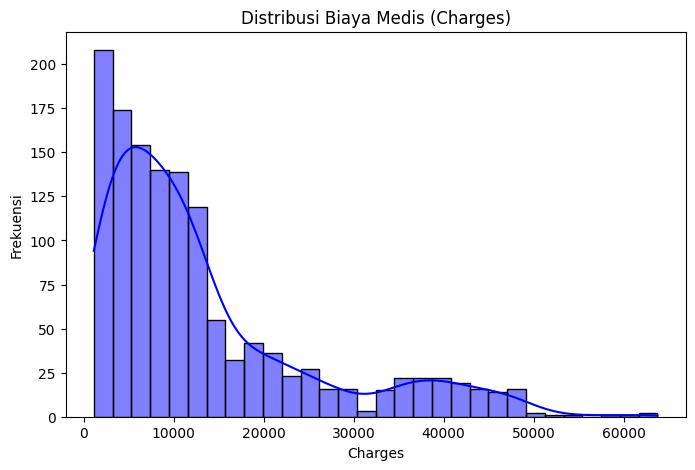

In [8]:
# Informasi umum dataset
print(df.info())

# Distribusi variabel target (charges)
plt.figure(figsize=(8, 5))
sns.histplot(df['charges'], kde=True, color='blue')
plt.title('Distribusi Biaya Medis (Charges)')
plt.xlabel('Charges')
plt.ylabel('Frekuensi')
plt.show()

In [9]:
# Memisahkan fitur dan target
X = df.drop(columns=['charges'])
y = df['charges']

# Menentukan kolom kategorikal untuk encoding
categorical_features = ['sex', 'smoker', 'region']

# Menggunakan ColumnTransformer untuk One-Hot Encoding
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first'), categorical_features)
    ], remainder='passthrough'
)

X_encoded = preprocessor.fit_transform(X)

# Membagi data menjadi train dan test (80:20)
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

print(f"Ukuran X_train: {X_train.shape}")
print(f"Ukuran X_test: {X_test.shape}")

Ukuran X_train: (1070, 8)
Ukuran X_test: (268, 8)


In [10]:
# Inisialisasi model
model = LinearRegression()

# Melatih model
model.fit(X_train, y_train)

# Melakukan prediksi pada data uji
y_pred = model.predict(X_test)

In [11]:
# Menghitung metrik evaluasi
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("=== Hasil Evaluasi Model ===")
print(f"R-squared (R2)      : {r2:.4f}")
print(f"Mean Squared Error  : {mse:.4f}")
print(f"Root Mean MSE (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error : {mae:.4f}")

=== Hasil Evaluasi Model ===
R-squared (R2)      : 0.7836
Mean Squared Error  : 33596915.8514
Root Mean MSE (RMSE): 5796.2847
Mean Absolute Error : 4181.1945
